In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.neural_network import MLPRegressor

from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error
)

from xgboost import XGBRegressor

import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

import warnings
warnings.filterwarnings("ignore")

In [2]:
import pandas as pd
import numpy as np

# File path
file_path = r"D:\MSC THESIS AAVAS\AFTER MID DEFENSE\Final Data for Modeling.xlsx"

# Load dataset
df = pd.read_excel(file_path)

# Display first 5 rows
df.head()

,SN,V85 Speed,Gradient,Radius of Curve,Carriageway Width,Left Shoulder Width,Left Shoulder Type,Right Shoulder Width,Right Shoulder Type,IRI
0,1,57.0,1.27,inf,5.5,0.9,Gravel,0.9,Gravel,3.70
1,2,33.0,2.92,46.0,5.5,0.9,Gravel,0.9,Gravel,4.51
2,3,43.0,7.97,inf,5.5,0.9,Gravel,0.9,Gravel,4.39
3,4,48.0,2.07,inf,5.5,0.9,Gravel,0.9,Gravel,4.69
4,5,36.0,1.21,16.0,5.5,0.9,Gravel,0.9,Gravel,5.57


In [3]:
# Check dataset dimensions
print("Dataset Shape:", df.shape)

# Display column names
print("\nColumn Names:")
print(df.columns.tolist())

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Display descriptive statistics
df.describe(include="all")

Dataset Shape: (175, 10)

Column Names:
['SN', 'V85 Speed', 'Gradient', 'Radius of Curve', 'Carriageway Width', 'Left Shoulder Width', 'Left Shoulder Type', 'Right Shoulder Width', 'Right Shoulder Type', 'IRI']

Missing Values:
SN                      0
V85 Speed               0
Gradient                0
Radius of Curve         0
Carriageway Width       0
Left Shoulder Width     0
Left Shoulder Type      0
Right Shoulder Width    0
Right Shoulder Type     0
IRI                     0
dtype: int64


,SN,V85 Speed,Gradient,Radius of Curve,Carriageway Width,Left Shoulder Width,Left Shoulder Type,Right Shoulder Width,Right Shoulder Type,IRI
count,175.000000,175.000000,175.000000,175.0,175.000000,175.000000,175,175.000000,175,175.000000
unique,NaN,NaN,NaN,NaN,NaN,NaN,4,NaN,3,NaN
top,NaN,NaN,NaN,NaN,NaN,NaN,Gravel,NaN,Paved,NaN
freq,NaN,NaN,NaN,NaN,NaN,NaN,73,NaN,72,NaN
mean,88.000000,45.170857,4.143740,inf,6.294611,0.606914,NaN,0.614057,NaN,5.969886
std,50.662281,10.326899,2.559308,NaN,0.900969,0.407746,NaN,0.400628,NaN,2.619041
min,1.000000,24.000000,0.070000,15.0,4.700000,0.000000,NaN,0.000000,NaN,2.150000
25%,44.500000,37.500000,1.792500,35.0,5.500000,0.090000,NaN,0.295000,NaN,3.755000
50%,88.000000,44.000000,4.090000,80.0,7.000000,0.640000,NaN,0.720000,NaN,5.440000
75%,131.500000,53.000000,6.142500,NaN,7.000000,1.000000,NaN,1.000000,NaN,8.420000


In [4]:
df.describe()

,SN,V85 Speed,Gradient,Radius of Curve,Carriageway Width,Left Shoulder Width,Right Shoulder Width,IRI
count,175.000000,175.000000,175.000000,175.0,175.000000,175.000000,175.000000,175.000000
mean,88.000000,45.170857,4.143740,inf,6.294611,0.606914,0.614057,5.969886
std,50.662281,10.326899,2.559308,NaN,0.900969,0.407746,0.400628,2.619041
min,1.000000,24.000000,0.070000,15.0,4.700000,0.000000,0.000000,2.150000
25%,44.500000,37.500000,1.792500,35.0,5.500000,0.090000,0.295000,3.755000
50%,88.000000,44.000000,4.090000,80.0,7.000000,0.640000,0.720000,5.440000
75%,131.500000,53.000000,6.142500,NaN,7.000000,1.000000,1.000000,8.420000
max,175.000000,74.000000,11.085000,inf,8.000000,1.130000,1.180000,12.050000


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 175 entries, 0 to 174
Data columns (total 10 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   SN                    175 non-null    int64  
 1   V85 Speed             175 non-null    float64
 2   Gradient              175 non-null    float64
 3   Radius of Curve       175 non-null    float64
 4   Carriageway Width     175 non-null    float64
 5   Left Shoulder Width   175 non-null    float64
 6   Left Shoulder Type    175 non-null    str    
 7   Right Shoulder Width  175 non-null    float64
 8   Right Shoulder Type   175 non-null    str    
 9   IRI                   175 non-null    float64
dtypes: float64(7), int64(1), str(2)
memory usage: 13.8 KB


In [6]:
df.isnull().sum()

SN                      0
V85 Speed               0
Gradient                0
Radius of Curve         0
Carriageway Width       0
Left Shoulder Width     0
Left Shoulder Type      0
Right Shoulder Width    0
Right Shoulder Type     0
IRI                     0
dtype: int64

In [7]:
df["Left Shoulder Type"] = df["Left Shoulder Type"].str.strip().str.lower().str.capitalize()
df["Right Shoulder Type"] = df["Right Shoulder Type"].str.strip().str.lower().str.capitalize()

In [8]:
df_encoded = pd.get_dummies(
    df,
    columns=["Left Shoulder Type", "Right Shoulder Type"],
    drop_first=True,
    dtype=int
)

In [9]:
# Replace infinity radius with 1500
df_encoded["Radius of Curve"] = pd.to_numeric(
    df_encoded["Radius of Curve"]
    .astype(str)
    .str.strip()
    .str.lower()
    .replace({"infinity": "1500", "inf": "1500", "∞": "1500"}),
    errors="raise"
)

In [10]:
# Variance Inflation Factor (VIF) for Multicollinearity Check

X_vif = df_encoded[
    [
        "Gradient",
        "Radius of Curve",
        "Carriageway Width",
        "Left Shoulder Width",
        "Right Shoulder Width",
        "Left Shoulder Type_Gravel",
        "Left Shoulder Type_Paved",
        "Right Shoulder Type_Gravel",
        "Right Shoulder Type_Paved",
        "IRI"
    ]
]

X_vif = X_vif.astype(float)
X_vif_const = sm.add_constant(X_vif)

vif_data = pd.DataFrame()
vif_data["Feature"] = X_vif_const.columns
vif_data["VIF"] = [
    variance_inflation_factor(X_vif_const.values, i)
    for i in range(X_vif_const.shape[1])
]

vif_data

,Feature,VIF
0,const,102.454292
1,Gradient,1.126564
2,Radius of Curve,1.116837
3,Carriageway Width,1.310317
4,Left Shoulder Width,6.332145
5,Right Shoulder Width,5.446793
6,Left Shoulder Type_Gravel,7.559131
7,Left Shoulder Type_Paved,7.373369
8,Right Shoulder Type_Gravel,6.147138
9,Right Shoulder Type_Paved,7.348267


In [11]:
# Calculate Average Shoulder Width

df_encoded["Average Shoulder Width"] = (
    df_encoded["Left Shoulder Width"] +
    df_encoded["Right Shoulder Width"]
) / 2

# Display first five rows
df_encoded[
    ["Left Shoulder Width", "Right Shoulder Width", "Average Shoulder Width"]
].head()

,Left Shoulder Width,Right Shoulder Width,Average Shoulder Width
0,0.9,0.9,0.9
1,0.9,0.9,0.9
2,0.9,0.9,0.9
3,0.9,0.9,0.9
4,0.9,0.9,0.9


In [12]:
# VIF Analysis with Average Shoulder Width

X_vif_avg = df_encoded[
    [
        "Gradient",
        "Radius of Curve",
        "Carriageway Width",
        "Average Shoulder Width",
        "Left Shoulder Type_Gravel",
        "Left Shoulder Type_Paved",
        "Right Shoulder Type_Gravel",
        "Right Shoulder Type_Paved",
        "IRI"
    ]
]

X_vif_avg = X_vif_avg.astype(float)

X_vif_avg_const = sm.add_constant(X_vif_avg)

vif_data_avg = pd.DataFrame()

vif_data_avg["Feature"] = X_vif_avg_const.columns

vif_data_avg["VIF"] = [
    variance_inflation_factor(X_vif_avg_const.values, i)
    for i in range(X_vif_avg_const.shape[1])
]

# Display VIF results
vif_data_avg

,Feature,VIF
0,const,99.970451
1,Gradient,1.122504
2,Radius of Curve,1.116506
3,Carriageway Width,1.278921
4,Average Shoulder Width,5.033221
5,Left Shoulder Type_Gravel,5.218109
6,Left Shoulder Type_Paved,5.103866
7,Right Shoulder Type_Gravel,4.870756
8,Right Shoulder Type_Paved,5.881904
9,IRI,1.841379


In [13]:
# VIF Analysis After Removing Shoulder Type Variables

X_vif_final = df_encoded[
    [
        "Gradient",
        "Radius of Curve",
        "Carriageway Width",
        "Average Shoulder Width",
        "IRI"
    ]
].copy()

# Convert to float
X_vif_final = X_vif_final.astype(float)

# Add constant
X_vif_final_const = sm.add_constant(X_vif_final)

# Calculate VIF
vif_data_final = pd.DataFrame()

vif_data_final["Feature"] = X_vif_final_const.columns

vif_data_final["VIF"] = [
    variance_inflation_factor(X_vif_final_const.values, i)
    for i in range(X_vif_final_const.shape[1])
]

# Display results
vif_data_final

,Feature,VIF
0,const,67.516669
1,Gradient,1.080176
2,Radius of Curve,1.060536
3,Carriageway Width,1.153301
4,Average Shoulder Width,1.568651
5,IRI,1.773518


In [14]:
# Compare VIF before and after removing Shoulder Types

vif_comparison = pd.merge(
    vif_data_avg,
    vif_data_final,
    on="Feature",
    how="outer",
    suffixes=("_With_Shoulder_Type", "_Without_Shoulder_Type")
)

vif_comparison = vif_comparison.round(3)

display(vif_comparison)

,Feature,VIF_With_Shoulder_Type,VIF_Without_Shoulder_Type
0,Average Shoulder Width,5.033,1.569
1,Carriageway Width,1.279,1.153
2,Gradient,1.123,1.080
3,IRI,1.841,1.774
4,Left Shoulder Type_Gravel,5.218,NaN
5,Left Shoulder Type_Paved,5.104,NaN
6,Radius of Curve,1.117,1.061
7,Right Shoulder Type_Gravel,4.871,NaN
8,Right Shoulder Type_Paved,5.882,NaN
9,const,99.970,67.517


In [15]:
# Final Feature Selection

X = df_encoded[
    [
        "Gradient",
        "Radius of Curve",
        "Carriageway Width",
        "Average Shoulder Width",
        "IRI"
    ]
]

# Target Variable
y = df_encoded["V85 Speed"]

In [16]:
print("Selected Independent Variables:")
print(X.columns.tolist())

print("\nNumber of Features:", X.shape[1])
print("Number of Observations:", X.shape[0])

print("\nTarget Variable:", y.name)

Selected Independent Variables:
['Gradient', 'Radius of Curve', 'Carriageway Width', 'Average Shoulder Width', 'IRI']

Number of Features: 5
Number of Observations: 175

Target Variable: V85 Speed


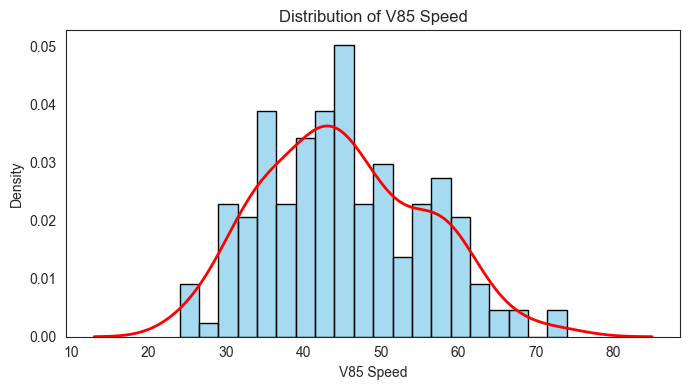

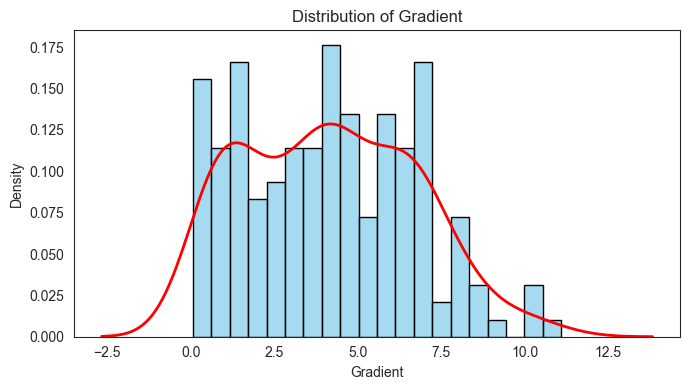

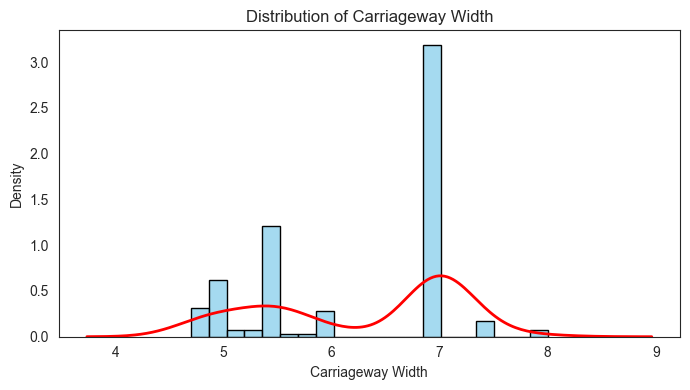

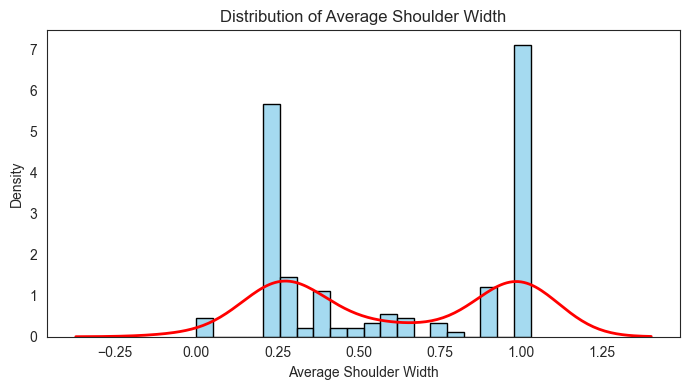

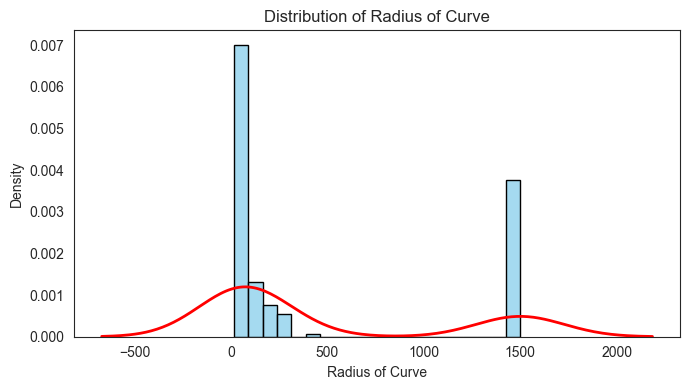

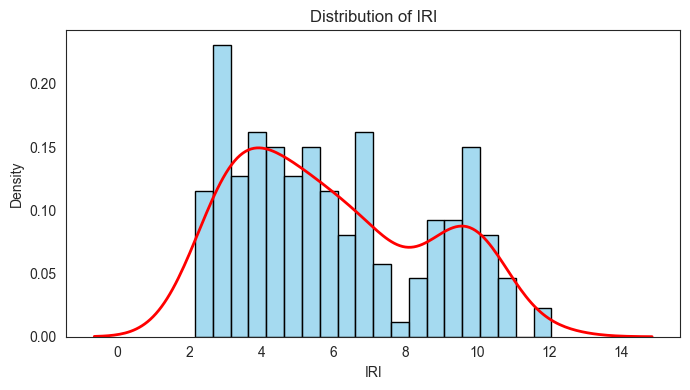

In [17]:
# Distribution Plots

num_cols = [
    "V85 Speed",
    "Gradient",
    "Carriageway Width",
    "Average Shoulder Width",
    "Radius of Curve",
    "IRI"
]

sns.set_style("white")

for col in num_cols:
    plt.figure(figsize=(7,4))

    sns.histplot(
        df_encoded[col],
        bins=20,
        stat="density",
        color="skyblue",
        edgecolor="black"
    )

    sns.kdeplot(
        df_encoded[col],
        color="red",
        linewidth=2
    )

    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Density")

    plt.tight_layout()
    plt.show()

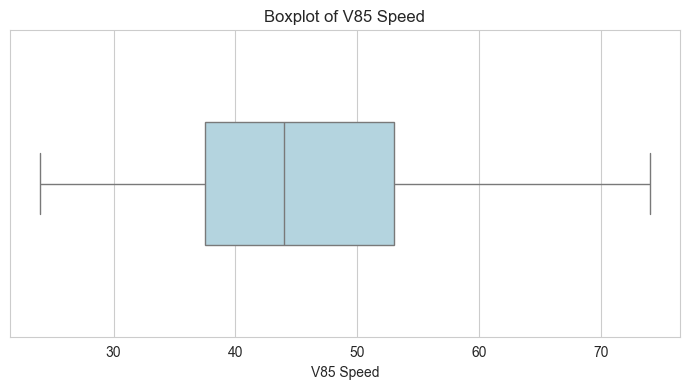

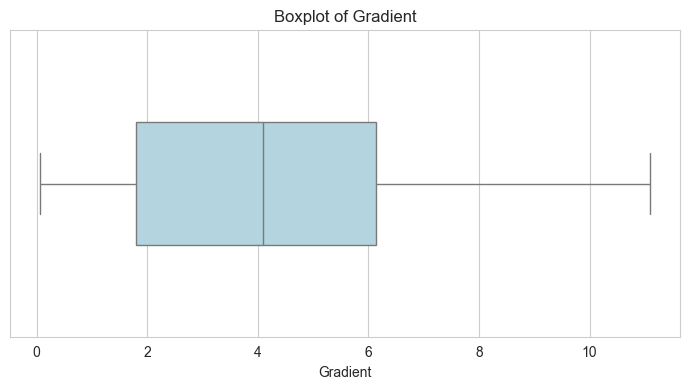

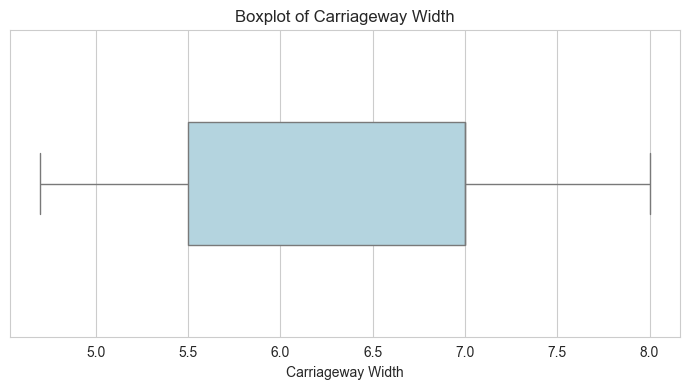

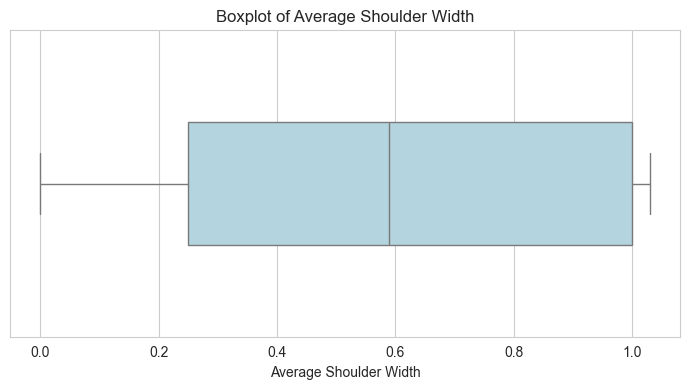

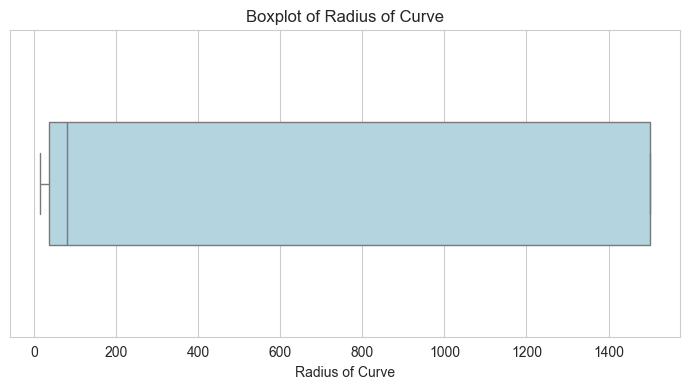

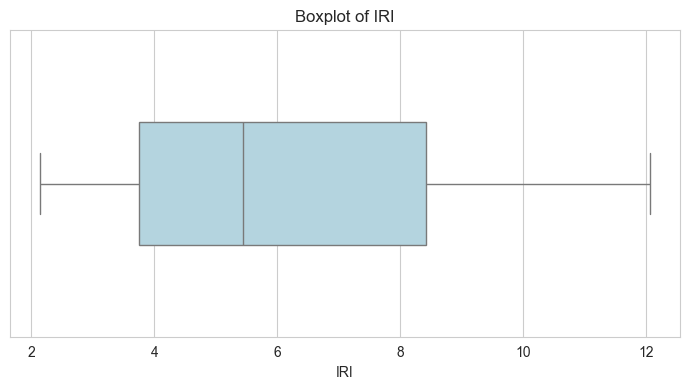

In [18]:
# Box Plots for Outlier Detection

num_cols = [
    "V85 Speed",
    "Gradient",
    "Carriageway Width",
    "Average Shoulder Width",
    "Radius of Curve",
    "IRI"
]

sns.set_style("whitegrid")

for col in num_cols:
    plt.figure(figsize=(7,4))

    sns.boxplot(
        x=df_encoded[col],
        color="lightblue",
        width=0.4
    )

    plt.title(f"Boxplot of {col}")
    plt.xlabel(col)

    plt.tight_layout()
    plt.show()

In [19]:
# Skewness Analysis

num_cols = [
    "V85 Speed",
    "Gradient",
    "Carriageway Width",
    "Average Shoulder Width",
    "Radius of Curve",
    "IRI"
]

skew_table = pd.DataFrame({
    "Variable": num_cols,
    "Skewness": df_encoded[num_cols].skew().values
})

skew_table

,Variable,Skewness
0,V85 Speed,0.288604
1,Gradient,0.251198
2,Carriageway Width,-0.401804
3,Average Shoulder Width,0.017076
4,Radius of Curve,0.956301
5,IRI,0.426386


In [20]:
# Correlation Matrix

num_cols = [
    "V85 Speed",
    "Gradient",
    "Carriageway Width",
    "Average Shoulder Width",
    "Radius of Curve",
    "IRI"
]

corr_matrix = df_encoded[num_cols].corr()

corr_matrix

,V85 Speed,Gradient,Carriageway Width,Average Shoulder Width,Radius of Curve,IRI
V85 Speed,1.000000,-0.089351,0.070966,-0.185663,0.559308,0.236338
Gradient,-0.089351,1.000000,-0.146781,-0.042299,-0.186188,-0.134750
Carriageway Width,0.070966,-0.146781,1.000000,-0.042953,0.028493,0.311065
Average Shoulder Width,-0.185663,-0.042299,-0.042953,1.000000,-0.075202,-0.575186
Radius of Curve,0.559308,-0.186188,0.028493,-0.075202,1.000000,0.166872
IRI,0.236338,-0.134750,0.311065,-0.575186,0.166872,1.000000


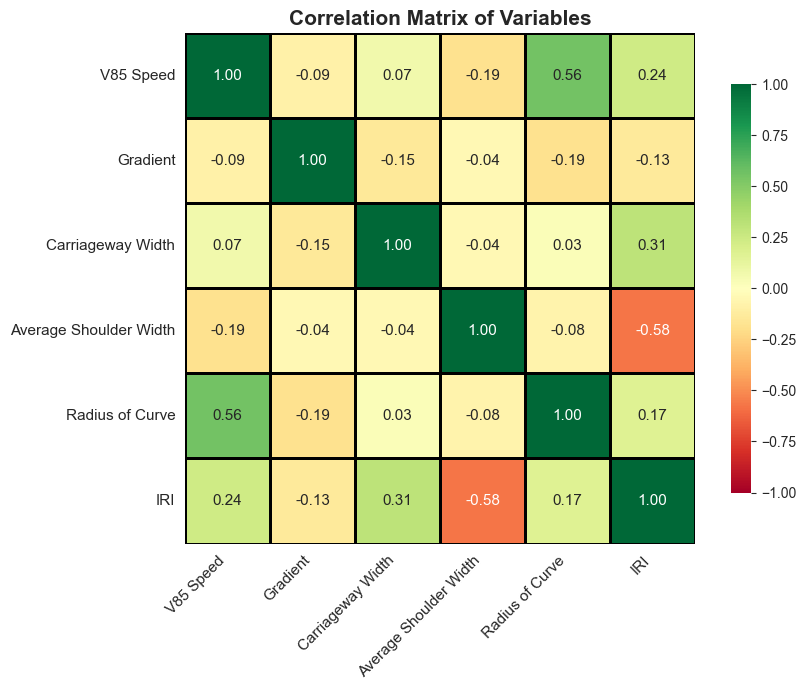

In [21]:
# Correlation Matrix

num_cols = [
    "V85 Speed",
    "Gradient",
    "Carriageway Width",
    "Average Shoulder Width",
    "Radius of Curve",
    "IRI"
]

corr_matrix = df_encoded[num_cols].corr()

# Plot Correlation Heatmap

sns.set_style("white")

plt.figure(figsize=(9, 7))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="RdYlGn",
    vmin=-1,
    vmax=1,
    center=0,
    fmt=".2f",
    linewidths=2,
    linecolor="black",
    square=True,
    annot_kws={"size": 11},
    cbar_kws={"shrink": 0.8}
)

plt.title(
    "Correlation Matrix of Variables",
    fontsize=15,
    fontweight="bold"
)

plt.xticks(rotation=45, ha="right", fontsize=11)
plt.yticks(rotation=0, fontsize=11)

plt.tight_layout()
plt.show()

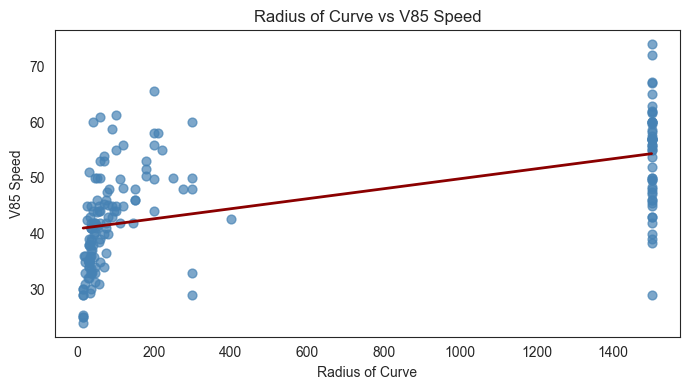

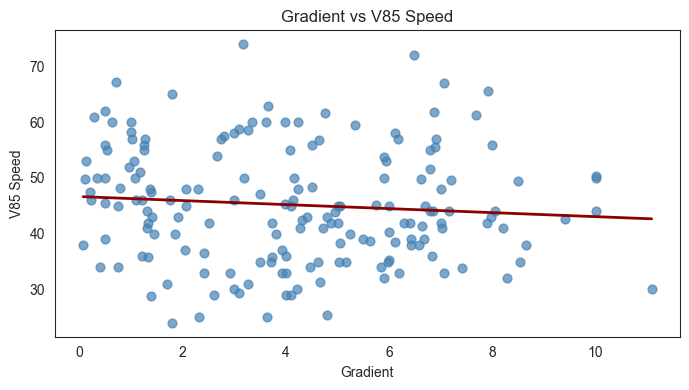

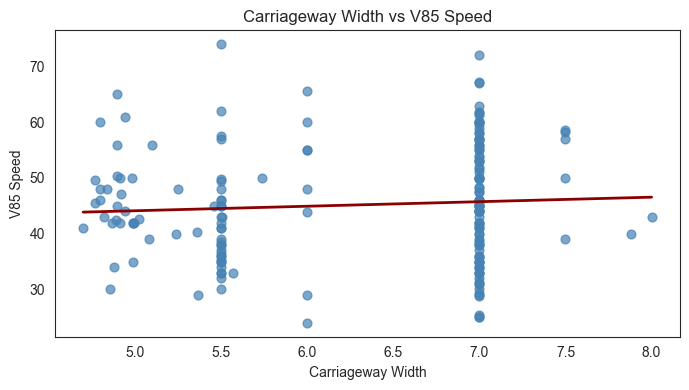

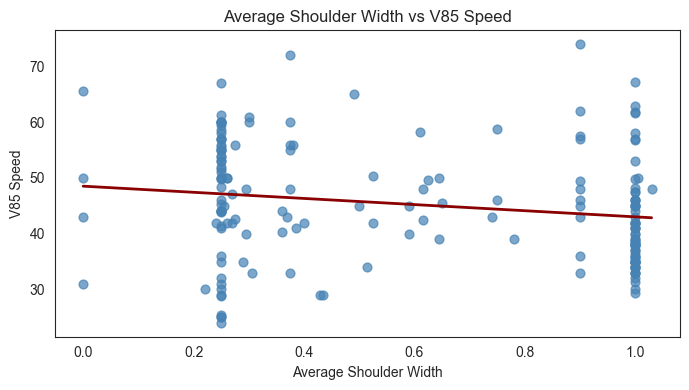

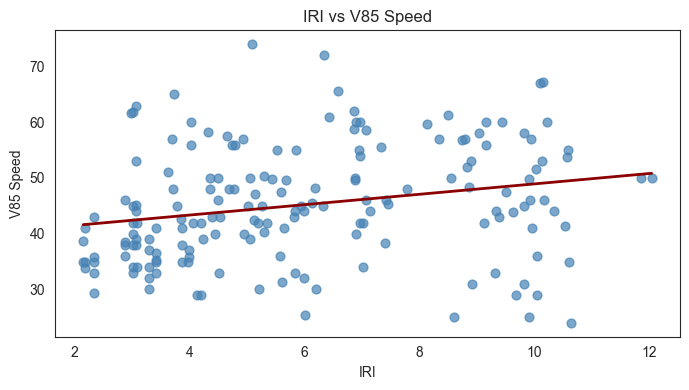

In [22]:
# Regression Plots: Independent Variables vs V85 Speed

predictor_cols = [
    "Radius of Curve",
    "Gradient",
    "Carriageway Width",
    "Average Shoulder Width",
    "IRI"
]

sns.set_style("white")

for col in predictor_cols:
    plt.figure(figsize=(7, 4))

    sns.regplot(
        x=df_encoded[col],
        y=df_encoded["V85 Speed"],
        scatter_kws={"s": 40, "color": "steelblue", "alpha": 0.7},
        line_kws={"color": "darkred", "linewidth": 2},
        ci=None
    )

    plt.title(f"{col} vs V85 Speed")
    plt.xlabel(col)
    plt.ylabel("V85 Speed")

    plt.tight_layout()
    plt.show()

In [23]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

print("X_train shape:", X_train.shape)
print("X_test shape :", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape :", y_test.shape)

X_train shape: (140, 5)
X_test shape : (35, 5)
y_train shape: (140,)
y_test shape : (35,)


In [24]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [25]:
print("Scaled Training Data Shape:", X_train_scaled.shape)
print("Scaled Testing Data Shape :", X_test_scaled.shape)

print("\nMean of Scaled Training Features:")
print(X_train_scaled.mean(axis=0))

print("\nStandard Deviation of Scaled Training Features:")
print(X_train_scaled.std(axis=0))

Scaled Training Data Shape: (140, 5)
Scaled Testing Data Shape : (35, 5)

Mean of Scaled Training Features:
[ 1.61775355e-16 -1.26882631e-17 -3.48927236e-16 -2.47421131e-16
 -5.86832170e-17]

Standard Deviation of Scaled Training Features:
[1. 1. 1. 1. 1.]


In [26]:
from sklearn.linear_model import LinearRegression

mlr = LinearRegression()

# Train MLR model using unscaled data
mlr.fit(X_train, y_train)

mlr

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [27]:
# Predictions using unscaled data

y_train_pred_mlr = mlr.predict(X_train)
y_test_pred_mlr = mlr.predict(X_test)

In [28]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
import numpy as np
import pandas as pd

# R2 Score
mlr_train_r2 = r2_score(y_train, y_train_pred_mlr)
mlr_test_r2 = r2_score(y_test, y_test_pred_mlr)

# Root Mean Squared Error (RMSE)
mlr_train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred_mlr))
mlr_test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred_mlr))

# Mean Absolute Error (MAE)
mlr_train_mae = mean_absolute_error(y_train, y_train_pred_mlr)
mlr_test_mae = mean_absolute_error(y_test, y_test_pred_mlr)

# Model Evaluation Table
mlr_results = pd.DataFrame({
    "Metric": ["R2", "RMSE", "MAE"],
    "Value": [mlr_test_r2, mlr_test_rmse, mlr_test_mae]
})

mlr_results

,Metric,Value
0,R2,0.143995
1,RMSE,7.422118
2,MAE,5.677677


In [29]:
# Training and Testing Performance Comparison

mlr_comparison = pd.DataFrame({
    "Metric": ["R2", "RMSE", "MAE"],
    "Training": [
        mlr_train_r2,
        mlr_train_rmse,
        mlr_train_mae
    ],
    "Testing": [
        mlr_test_r2,
        mlr_test_rmse,
        mlr_test_mae
    ]
})

mlr_comparison = mlr_comparison.round(4)

mlr_comparison

,Metric,Training,Testing
0,R2,0.3627,0.1440
1,RMSE,8.6145,7.4221
2,MAE,6.6650,5.6777


In [30]:
# Table of MLR Coefficients

coef_table_mlr = pd.DataFrame({
    "Variable": X.columns,
    "Coefficient": mlr.coef_
})

# Add intercept as first row
intercept_row = pd.DataFrame({
    "Variable": ["Constant"],
    "Coefficient": [mlr.intercept_]
})

coef_table_mlr = pd.concat(
    [intercept_row, coef_table_mlr],
    ignore_index=True
)

coef_table_mlr["Coefficient"] = coef_table_mlr["Coefficient"].round(4)

coef_table_mlr

,Variable,Coefficient
0,Constant,37.3688
1,Gradient,0.0490
2,Radius of Curve,0.0096
3,Carriageway Width,0.5603
4,Average Shoulder Width,-3.2427
5,IRI,0.2678


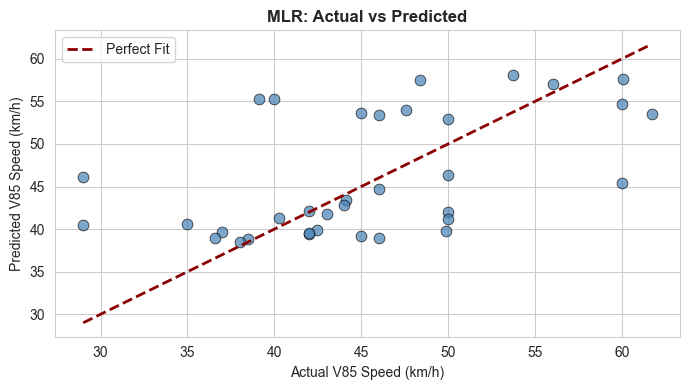

In [31]:
# MLR: Actual vs Predicted V85 Speed

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

plt.figure(figsize=(7, 4))

# Scatter plot
sns.scatterplot(
    x=y_test,
    y=y_test_pred_mlr,
    color="steelblue",
    s=60,
    alpha=0.7,
    edgecolor="black"
)

# Perfect fit line
min_val = min(y_test.min(), y_test_pred_mlr.min())
max_val = max(y_test.max(), y_test_pred_mlr.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    color="darkred",
    linestyle="--",
    linewidth=2,
    label="Perfect Fit"
)

plt.xlabel("Actual V85 Speed (km/h)")
plt.ylabel("Predicted V85 Speed (km/h)")
plt.title("MLR: Actual vs Predicted", fontsize=12, fontweight="bold")

plt.legend()
plt.tight_layout()
plt.show()

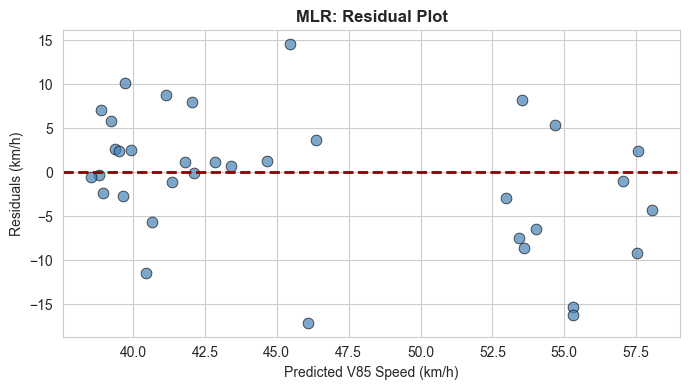

In [32]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_style("whitegrid")

# Calculate residuals
mlr_residuals = y_test - y_test_pred_mlr

plt.figure(figsize=(7, 4))

sns.scatterplot(
    x=y_test_pred_mlr,
    y=mlr_residuals,
    color="steelblue",
    s=60,
    alpha=0.7,
    edgecolor="black"
)

plt.axhline(
    y=0,
    linestyle="--",
    color="darkred",
    linewidth=2
)

plt.xlabel("Predicted V85 Speed (km/h)")
plt.ylabel("Residuals (km/h)")
plt.title("MLR: Residual Plot", fontsize=12, fontweight="bold")

plt.tight_layout()
plt.show()

In [33]:
# Final MLR Model Performance

mlr_final = pd.DataFrame({
    "Model": ["MLR"],
    "R2": [round(mlr_test_r2, 3)],
    "RMSE": [round(mlr_test_rmse, 3)],
    "MAE": [round(mlr_test_mae, 3)]
})

mlr_final

,Model,R2,RMSE,MAE
0,MLR,0.144,7.422,5.678


In [34]:
from sklearn.ensemble import RandomForestRegressor

# Initialize Random Forest Model
rf = RandomForestRegressor(
    random_state=42
)

# Train using unscaled data
rf.fit(X_train, y_train)

rf

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""friedman_mse"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in Poisson deviance to find splits.Training using ""absolute_error"" is significantly slowerthan when using ""squared_error""... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsample

In [35]:
# Predictions using Random Forest

y_train_pred_rf = rf.predict(X_train)
y_test_pred_rf = rf.predict(X_test)

In [36]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
import numpy as np
import pandas as pd

# R2 Score
rf_train_r2 = r2_score(y_train, y_train_pred_rf)
rf_test_r2 = r2_score(y_test, y_test_pred_rf)

# Root Mean Squared Error (RMSE)
rf_train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred_rf))
rf_test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred_rf))

# Mean Absolute Error (MAE)
rf_train_mae = mean_absolute_error(y_train, y_train_pred_rf)
rf_test_mae = mean_absolute_error(y_test, y_test_pred_rf)

# Model Evaluation Table
rf_results = pd.DataFrame({
    "Metric": ["R2", "RMSE", "MAE"],
    "Value": [rf_test_r2, rf_test_rmse, rf_test_mae]
})

rf_results

,Metric,Value
0,R2,0.150287
1,RMSE,7.394791
2,MAE,5.566614


In [37]:
# Random Forest Training and Testing Performance

rf_comparison = pd.DataFrame({
    "Metric": ["R2", "RMSE", "MAE"],
    "Training": [
        rf_train_r2,
        rf_train_rmse,
        rf_train_mae
    ],
    "Testing": [
        rf_test_r2,
        rf_test_rmse,
        rf_test_mae
    ]
})

rf_comparison = rf_comparison.round(4)

rf_comparison

,Metric,Training,Testing
0,R2,0.9212,0.1503
1,RMSE,3.0283,7.3948
2,MAE,2.2047,5.5666


In [38]:
# Random Forest Feature Importance

rf_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf.feature_importances_
}).sort_values(by="Importance", ascending=False)

rf_importance

,Feature,Importance
1,Radius of Curve,0.618770
0,Gradient,0.148860
4,IRI,0.129489
3,Average Shoulder Width,0.060608
2,Carriageway Width,0.042272


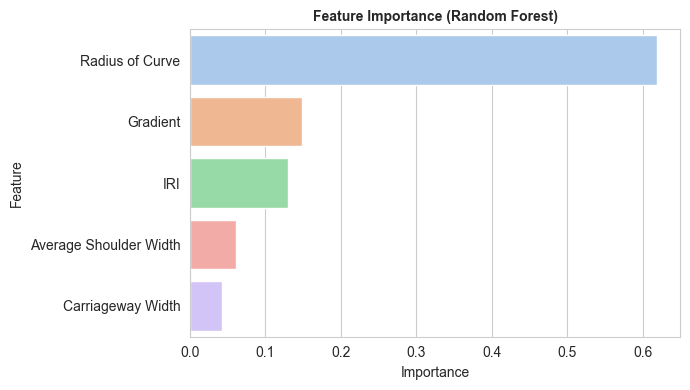

In [39]:
# Random Forest Feature Importance Bar Plot

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

plt.figure(figsize=(7, 4))

sns.barplot(
    x="Importance",
    y="Feature",
    data=rf_importance,
    hue="Feature",
    palette="pastel",
    dodge=False,
    legend=False
)

plt.title(
    "Feature Importance (Random Forest)",
    fontsize=10,
    fontweight="bold"
)

plt.xlabel("Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

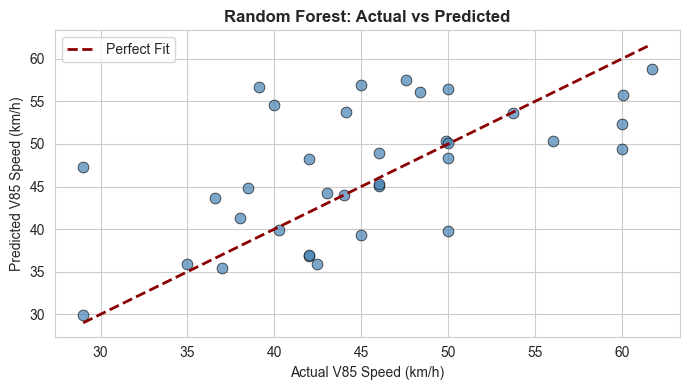

In [40]:
# Random Forest: Actual vs Predicted V85 Speed

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

plt.figure(figsize=(7, 4))

# Scatter plot using seaborn
sns.scatterplot(
    x=y_test,
    y=y_test_pred_rf,
    color="steelblue",
    s=60,
    alpha=0.7,
    edgecolor="black"
)

# Perfect fit line (45-degree line)
min_val = min(y_test.min(), y_test_pred_rf.min())
max_val = max(y_test.max(), y_test_pred_rf.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    color="darkred",
    linestyle="--",
    linewidth=2,
    label="Perfect Fit"
)

plt.xlabel("Actual V85 Speed (km/h)")
plt.ylabel("Predicted V85 Speed (km/h)")
plt.title(
    "Random Forest: Actual vs Predicted",
    fontsize=12,
    fontweight="bold"
)

plt.legend()
plt.tight_layout()
plt.show()

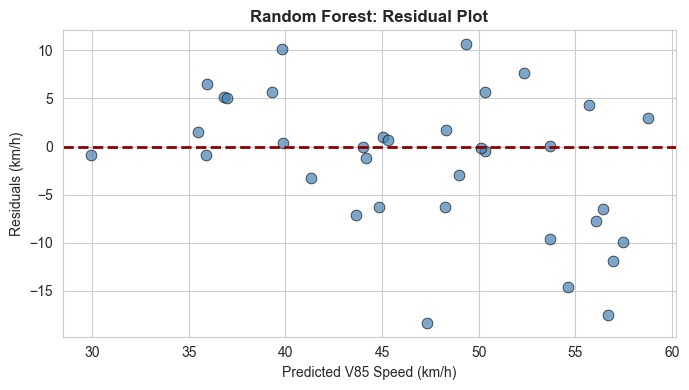

In [41]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_style("whitegrid")

# Calculate residuals
rf_residuals = y_test - y_test_pred_rf

plt.figure(figsize=(7, 4))

sns.scatterplot(
    x=y_test_pred_rf,
    y=rf_residuals,
    color="steelblue",
    s=60,
    alpha=0.7,
    edgecolor="black"
)

# Zero residual reference line
plt.axhline(
    y=0,
    linestyle="--",
    color="darkred",
    linewidth=2
)

plt.xlabel("Predicted V85 Speed (km/h)")
plt.ylabel("Residuals (km/h)")
plt.title(
    "Random Forest: Residual Plot",
    fontsize=12,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

In [42]:
# Final Random Forest Model Performance

rf_final = pd.DataFrame({
    "Model": ["Random Forest"],
    "R2": [round(rf_test_r2, 3)],
    "RMSE": [round(rf_test_rmse, 3)],
    "MAE": [round(rf_test_mae, 3)]
})

rf_final

,Model,R2,RMSE,MAE
0,Random Forest,0.15,7.395,5.567


In [43]:
# MLR and Random Forest Comparison

model_comparison = pd.concat(
    [mlr_final, rf_final],
    ignore_index=True
)

model_comparison

,Model,R2,RMSE,MAE
0,MLR,0.144,7.422,5.678
1,Random Forest,0.150,7.395,5.567


In [44]:
# Hyperparameter Grid for Random Forest

param_grid_rf = {
    "n_estimators": [100, 200, 300],
    "max_depth": [None, 5, 10, 15],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2"]
}

In [45]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestRegressor

grid_rf = GridSearchCV(
    estimator=RandomForestRegressor(random_state=42),
    param_grid=param_grid_rf,
    cv=5,
    scoring="r2",
    n_jobs=-1,
    verbose=1
)

# Train using UNSCALED data
grid_rf.fit(X_train, y_train)

print("Tuning completed")
print("Best Parameters:", grid_rf.best_params_)
print("Best CV Score:", round(grid_rf.best_score_, 3))

Fitting 5 folds for each of 216 candidates, totalling 1080 fits
Tuning completed
Best Parameters: {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 100}
Best CV Score: 0.468


In [46]:
# Extract Best Tuned Random Forest Model

best_rf = grid_rf.best_estimator_

best_rf

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""friedman_mse"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in Poisson deviance to find splits.Training using ""absolute_error"" is significantly slowerthan when using ""squared_error""... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsam

In [47]:
# Predictions Using Tuned Random Forest Model

y_train_pred_rf_tuned = best_rf.predict(X_train)

y_test_pred_rf_tuned = best_rf.predict(X_test)

In [48]:
# Model Evaluation Metrics

rf_tuned_train_r2 = r2_score(y_train, y_train_pred_rf_tuned)
rf_tuned_test_r2 = r2_score(y_test, y_test_pred_rf_tuned)

rf_tuned_train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred_rf_tuned))
rf_tuned_test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred_rf_tuned))

rf_tuned_train_mae = mean_absolute_error(y_train, y_train_pred_rf_tuned)
rf_tuned_test_mae = mean_absolute_error(y_test, y_test_pred_rf_tuned)

rf_tuned_results = pd.DataFrame({
    "Metric": ["R2", "RMSE", "MAE"],
    "Value": [rf_tuned_test_r2, rf_tuned_test_rmse, rf_tuned_test_mae]
})

rf_tuned_results

,Metric,Value
0,R2,0.301258
1,RMSE,6.705761
2,MAE,5.147448


In [49]:
# Tuned Random Forest Training and Testing Performance

rf_tuned_comparison = pd.DataFrame({
    "Metric": ["R2", "RMSE", "MAE"],
    "Training": [
        rf_tuned_train_r2,
        rf_tuned_train_rmse,
        rf_tuned_train_mae
    ],
    "Testing": [
        rf_tuned_test_r2,
        rf_tuned_test_rmse,
        rf_tuned_test_mae
    ]
})

rf_tuned_comparison = rf_tuned_comparison.round(4)

rf_tuned_comparison

,Metric,Training,Testing
0,R2,0.8239,0.3013
1,RMSE,4.5280,6.7058
2,MAE,3.3213,5.1474


In [50]:
# Final Tuned Random Forest Results

rf_tuned_final = pd.DataFrame({
    "Model": ["Tuned Random Forest"],
    "R2": [round(rf_tuned_test_r2, 3)],
    "RMSE": [round(rf_tuned_test_rmse, 3)],
    "MAE": [round(rf_tuned_test_mae, 3)]
})

rf_tuned_final

,Model,R2,RMSE,MAE
0,Tuned Random Forest,0.301,6.706,5.147


In [51]:
# Baseline vs Tuned Random Forest Comparison

rf_model_comparison = pd.concat(
    [rf_final, rf_tuned_final],
    ignore_index=True
)

rf_model_comparison

,Model,R2,RMSE,MAE
0,Random Forest,0.150,7.395,5.567
1,Tuned Random Forest,0.301,6.706,5.147


In [52]:
# Feature Importance of Tuned Random Forest Model

rf_tuned_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": best_rf.feature_importances_
}).sort_values(by="Importance", ascending=False)

rf_tuned_importance

,Feature,Importance
1,Radius of Curve,0.560390
0,Gradient,0.167172
4,IRI,0.161309
3,Average Shoulder Width,0.071114
2,Carriageway Width,0.040016


In [53]:
from xgboost import XGBRegressor

xgb = XGBRegressor(
    random_state=42,
    objective="reg:squarederror"
)

# Train using unscaled data
xgb.fit(X_train, y_train)

xgb

,"objective objective: typing.Union[str, xgboost.sklearn._SklObjWProto, typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]], NoneType]Specify the learning task and the corresponding learning objective or a customobjective function to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'reg:squarederror'
,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API `... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,False
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes

In [54]:
# Predictions Using XGBoost Model

y_train_pred_xgb = xgb.predict(X_train)
y_test_pred_xgb = xgb.predict(X_test)

In [55]:
# Model Evaluation Metrics

xgb_train_r2 = r2_score(y_train, y_train_pred_xgb)
xgb_test_r2 = r2_score(y_test, y_test_pred_xgb)

xgb_train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred_xgb))
xgb_test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred_xgb))

xgb_train_mae = mean_absolute_error(y_train, y_train_pred_xgb)
xgb_test_mae = mean_absolute_error(y_test, y_test_pred_xgb)

xgb_results = pd.DataFrame({
    "Metric": ["R2", "RMSE", "MAE"],
    "Value": [xgb_test_r2, xgb_test_rmse, xgb_test_mae]
})

xgb_results

,Metric,Value
0,R2,-0.079419
1,RMSE,8.334599
2,MAE,6.601278


In [56]:
# XGBoost Training and Testing Performance

xgb_comparison = pd.DataFrame({
    "Metric": ["R2", "RMSE", "MAE"],
    "Training": [
        xgb_train_r2,
        xgb_train_rmse,
        xgb_train_mae
    ],
    "Testing": [
        xgb_test_r2,
        xgb_test_rmse,
        xgb_test_mae
    ]
})

xgb_comparison = xgb_comparison.round(4)

xgb_comparison

,Metric,Training,Testing
0,R2,1.0000,-0.0794
1,RMSE,0.0082,8.3346
2,MAE,0.0056,6.6013


In [57]:
# Final XGBoost Model Performance

xgb_final = pd.DataFrame({
    "Model": ["XGBoost"],
    "R2": [round(xgb_test_r2, 3)],
    "RMSE": [round(xgb_test_rmse, 3)],
    "MAE": [round(xgb_test_mae, 3)]
})

xgb_final

,Model,R2,RMSE,MAE
0,XGBoost,-0.079,8.335,6.601


In [58]:
# Hyperparameter Grid for XGBoost

param_grid_xgb = {
    "n_estimators": [100, 200],
    "max_depth": [3, 4, 5],
    "learning_rate": [0.01, 0.05, 0.1],
    "subsample": [0.7, 0.8, 1.0],
    "colsample_bytree": [0.7, 0.8, 1.0]
}

In [59]:
from sklearn.model_selection import GridSearchCV
from xgboost import XGBRegressor

grid_xgb = GridSearchCV(
    estimator=XGBRegressor(
        random_state=42,
        objective="reg:squarederror"
    ),
    param_grid=param_grid_xgb,
    cv=5,
    scoring="r2",
    n_jobs=-1,
    verbose=1
)

# Train using unscaled data
grid_xgb.fit(X_train, y_train)

print("Tuning Completed")
print("Best Parameters:", grid_xgb.best_params_)
print("Best CV Score:", round(grid_xgb.best_score_, 3))

Fitting 5 folds for each of 162 candidates, totalling 810 fits
Tuning Completed
Best Parameters: {'colsample_bytree': 1.0, 'learning_rate': 0.01, 'max_depth': 3, 'n_estimators': 200, 'subsample': 0.8}
Best CV Score: 0.44


In [60]:
# Extract Best Tuned XGBoost Model

best_xgb = grid_xgb.best_estimator_

best_xgb

,"objective objective: typing.Union[str, xgboost.sklearn._SklObjWProto, typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]], NoneType]Specify the learning task and the corresponding learning objective or a customobjective function to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'reg:squarederror'
,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API `... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,1.0
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,False
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes 

In [61]:
# Predictions Using Tuned XGBoost Model

y_train_pred_xgb_tuned = best_xgb.predict(X_train)

y_test_pred_xgb_tuned = best_xgb.predict(X_test)

In [62]:
# Model Evaluation Metrics

xgb_tuned_train_r2 = r2_score(y_train, y_train_pred_xgb_tuned)
xgb_tuned_test_r2 = r2_score(y_test, y_test_pred_xgb_tuned)

xgb_tuned_train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred_xgb_tuned))
xgb_tuned_test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred_xgb_tuned))

xgb_tuned_train_mae = mean_absolute_error(y_train, y_train_pred_xgb_tuned)
xgb_tuned_test_mae = mean_absolute_error(y_test, y_test_pred_xgb_tuned)

xgb_tuned_results = pd.DataFrame({
    "Metric": ["R2", "RMSE", "MAE"],
    "Value": [xgb_tuned_test_r2, xgb_tuned_test_rmse, xgb_tuned_test_mae]
})

xgb_tuned_results

,Metric,Value
0,R2,0.227233
1,RMSE,7.052027
2,MAE,5.449813


In [63]:
# Tuned XGBoost Training and Testing Performance

xgb_tuned_comparison = pd.DataFrame({
    "Metric": ["R2", "RMSE", "MAE"],
    "Training": [
        xgb_tuned_train_r2,
        xgb_tuned_train_rmse,
        xgb_tuned_train_mae
    ],
    "Testing": [
        xgb_tuned_test_r2,
        xgb_tuned_test_rmse,
        xgb_tuned_test_mae
    ]
})

xgb_tuned_comparison = xgb_tuned_comparison.round(4)

xgb_tuned_comparison

,Metric,Training,Testing
0,R2,0.6984,0.2272
1,RMSE,5.9265,7.0520
2,MAE,4.4855,5.4498


In [64]:
# Final Tuned XGBoost Model Performance

xgb_tuned_final = pd.DataFrame({
    "Model": ["Tuned XGBoost"],
    "R2": [round(xgb_tuned_test_r2, 3)],
    "RMSE": [round(xgb_tuned_test_rmse, 3)],
    "MAE": [round(xgb_tuned_test_mae, 3)]
})

xgb_tuned_final

,Model,R2,RMSE,MAE
0,Tuned XGBoost,0.227,7.052,5.45
